# The learned surrogate approach against the plant: what a test-set score does not tell

**Question:** The state of the art judges a learned surrogate of a comminution model by its error against that model; what does the same surrogate say about the ten real HP500 surveys, and does the product's autoencoder warn when the surrogate is outside its domain?

- **Level:** 3, State of the art
- **Prerequisites:** notebook 02 of this topic and notebook 01 of topic 05-real-surveys
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- state what the learned-surrogate state of the art claims and how it is validated;
- apply that same approach, the product's own surrogate, to the ten surveys and compare it with the measurement;
- find the input range where the network stops being a model of the engine, and show what it returns outside it;
- say whether the product's autoencoder warns at that point, what its alarms at the surveys respond to, and what that implies for how the surrogate may be used.

## Setup

The same four libraries as the rest of the topic.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

The imports add the survey reader and the calibrated-lane operating point of topic 05, the readers of the raw network and autoencoder, the applicability rule and the sweep ranges of the training domain, with CrusherCal's public error metric.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from collections import Counter
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import loo
from pipeline.model import sweep
from pipeline.model.bundles import (
    anomaly_graph, anomaly_score, applicability, engine_outputs, load_bundle, surrogate_graph, surrogate_predict)
from pipeline.model.crusher import Operating, evaluate, operating_from_survey
from pipeline.stages.evaluate import r2_mape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Data

The ten HP500 surveys, and the two released models. The surrogate and the autoencoder are released ChancaDEM models, trained by the product's own pipeline on a Latin-hypercube sweep of the engine and committed with their contracts (`surrogate-model`, `anomaly-model`). Licence class: MIT, as the rest of the repository; the training data is synthetic, drawn from the engine. The survey rows are from Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919, licence class CC BY 4.0. Files read: `data/examples/hp500-surveys.csv`, the reference operating point `data/derived/manifests/S01.json` and the models under `data/derived/models/`.

The cell reads the surveys and the S01 operating point, fixes the models folder, and loads the two contracts, which carry the training ranges.

In [2]:
# Read the surveys and the S01 operating point, fix the models folder and load the two contracts
surveys = read_surveys().accepted
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
base = Operating(**manifest["params"])
models_dir = ROOT / "data" / "derived" / "models"
surrogate_bundle = load_bundle("surrogate-model", models_dir)
anomaly_bundle = load_bundle("anomaly-model", models_dir)
measured = np.array([s.feed_tph for s in surveys])
print("surveys:", len(surveys), "| measured throughput range [t/h]:", measured.min(), measured.max())

surveys: 10 | measured throughput range [t/h]: 813.0 1639.0


## Method

**What is run.** The product's surrogate is the learned-surrogate approach in the sense of the next section: a small network that emulates a phenomenological comminution model. The method of this notebook is the product's, the engine and its released network, run at the operating points of the ten surveys. The cell builds each survey's operating point on the calibrated lane, which is what the surveys are, and compares its inputs with the training domain of the network. From here to the end of the extrapolation the network and the autoencoder are read through their raw graphs (`surrogate_graph`, `anomaly_graph`), which skip the applicability rule on purpose, because what they return outside their domain is the evidence; the rule comes at the end. It prints the ore competence A*b of the calibrated lane next to the range the network was trained on, and the inputs of each survey that fall outside.

In [3]:
# Build the calibrated operating point of each survey and compare its inputs with the training domain
calibrated = [operating_from_survey(s.css_mm, s.f80_mm) for s in surveys]
domain = sweep.RANGES["cone-sec"]
print("ore A*b of the calibrated lane:", calibrated[0].ore_axb, "| training range:", domain["ore_axb"])
outside = {}
for s, o in zip(surveys, calibrated):
    outside[s.survey] = [k for k in domain if not domain[k][0] <= getattr(o, k) <= domain[k][1]]
print("inputs outside the training range, per survey:")
for survey, names in outside.items():
    print(f"  {survey:2d}: {names}")

ore A*b of the calibrated lane: 677.3 | training range: (30, 110)
inputs outside the training range, per survey:
   1: ['ore_axb']
   2: ['ore_axb']
   3: ['feed_x63_mm', 'ore_axb']
   4: ['ore_axb']
   5: ['feed_x63_mm', 'ore_axb']
   6: ['ore_axb']
   7: ['ore_axb']
   8: ['ore_axb']
   9: ['ore_axb']
  10: ['ore_axb']


All ten surveys carry an ore competence far above the training range, and surveys 3 and 5 also a feed x63 outside it. The next section runs the literature's protocol on the network before asking what happens at these points.

## State of the art

**The protocol, run.** The test-set score of that literature is run here on the product's network with a small independent draw, 60 points per machine with the evaluation's seed, so that the notebook shows what the score is before asking what it misses. The cell scores P80 and the throughput of the released surrogate against the engine on the points the engine accepts.

In [4]:
# Run the test-set protocol: R2 and MAPE of P80 and throughput on a small independent draw
test_points = sweep.label(sweep.draw(60, 67890))
answers = [surrogate_predict(r.op, models_dir)[0] for r in test_points]
for key, field in (("p80_mm", "p80"), ("throughput_tph", "throughput_tph")):
    truth_values = np.array([getattr(r, field) for r in test_points])
    network_values = np.array([a[key] for a in answers])
    r2, error = r2_mape(network_values, truth_values)
    print(f"{key:15s} test points {len(test_points)}  R2 {r2:.4f}  MAPE {error:.2f} %")

p80_mm          test points 276  R2 0.9971  MAPE 4.22 %
throughput_tph  test points 276  R2 0.9984  MAPE 5.05 %


**The source.** Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) train a deep neural network to approximate the phenomenological models of a comminution circuit, in order to run circuit simulations faster. The product's framework card for this topic records the same reading of that work: a surrogate of a model and not of plant data, validated against the model it emulates, offline, reporting neither a held-out industrial comparison nor an uncertainty; the card also records a speed-up of about three thousand and error figures well under one percent, which are that paper's figures and not reproduced here, since neither its circuit nor its code is in this repository. What can be run is the approach, on the product's own engine.

Its protocol is a test-set score: a held-out draw from the same distribution as the training data, compared with the teacher. Notebook 02 ran it: R squared between 0.979 and 0.998. The question here is the one that protocol cannot ask: what does the surrogate say about a plant? The cell runs it at the ten surveys in two ways. The first is the honest one the network can do: the operating point with the calibration off and the ore at the edge of its training range, A*b = 100, which is what a user who stays inside the domain would have. The second is the point as the calibrated lane has it, with A*b = 677, far outside the range. For each it prints the mean absolute error of the throughput against the measurement, with the teacher's, the synthetic engine, and the calibrated backbone's for reference, and then the survey-by-survey values of the two network lines.

In [5]:
# Mean throughput error against the measurement: the network in and out of its domain, its teacher, the backbone
inside = [replace(o, calibrated=False, ore_axb=100.0, ore_wi=sweep.wi_of_axb(100.0)) for o in calibrated]
far = [replace(o, calibrated=False) for o in calibrated]
network_inside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in inside])
network_outside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in far])
teacher_inside = np.array([evaluate(o).throughput_tph for o in inside])
backbone_tph = np.array([evaluate(o).throughput_tph for o in calibrated])
rows = (("surrogate, ore at the domain edge (A*b = 100)", network_inside),
        ("its teacher, the synthetic engine (A*b = 100)", teacher_inside),
        ("calibrated backbone (the engine's calibrated lane)", backbone_tph),
        ("surrogate at the calibrated lane's ore (A*b = 677)", network_outside))
for name, values in rows:
    print(f"{name:52s} MAPE {loo.mape(measured, values):7.2f} %")
print("survey  measured  surrogate A*b = 100  surrogate A*b = 677  [t/h]")
for i, s in enumerate(surveys):
    print(f"{s.survey:6d} {measured[i]:9.0f} {network_inside[i]:19.1f} {network_outside[i]:19.1f}")

surrogate, ore at the domain edge (A*b = 100)        MAPE   24.78 %
its teacher, the synthetic engine (A*b = 100)        MAPE   21.72 %
calibrated backbone (the engine's calibrated lane)   MAPE   11.55 %
surrogate at the calibrated lane's ore (A*b = 677)   MAPE  118.20 %
survey  measured  surrogate A*b = 100  surrogate A*b = 677  [t/h]
     1      1639               924.0              2512.6
     2      1267               924.0              2513.6
     3      1240               851.6              2438.9
     4      1034               853.2              2429.2
     5      1124               852.6              2435.4
     6       813               758.1              2319.0
     7      1050               728.3              2275.6
     8      1138               803.9              2364.6
     9       820               758.1              2318.5
    10      1334               935.7              2528.1


The figure draws the four estimates against the measured throughput, survey by survey, so that the gaps are visible one at a time.

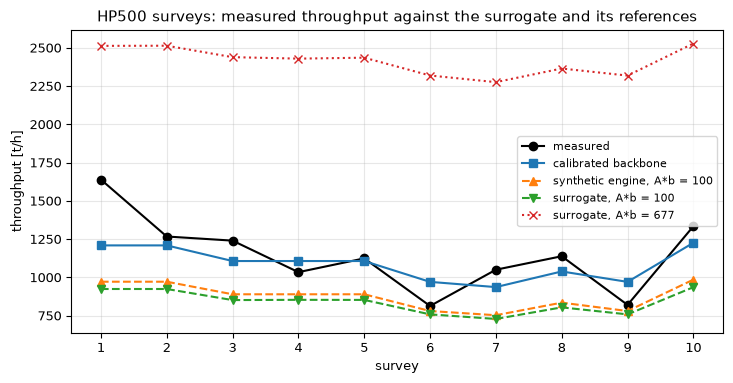

In [6]:
# Plot the measured throughput and the four estimates survey by survey
fig, ax = plt.subplots()
numbers = [s.survey for s in surveys]
ax.plot(numbers, measured, "ko-", label="measured")
ax.plot(numbers, backbone_tph, "s-", label="calibrated backbone")
ax.plot(numbers, teacher_inside, "^--", label="synthetic engine, A*b = 100")
ax.plot(numbers, network_inside, "v--", label="surrogate, A*b = 100")
ax.plot(numbers, network_outside, "x:", label="surrogate, A*b = 677")
ax.set_xticks(numbers)
ax.set_xlabel("survey")
ax.set_ylabel("throughput [t/h]")
ax.set_title("HP500 surveys: measured throughput against the surrogate and its references")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Four of the five lines run together at roughly the plant's level, within a few hundred t/h: the calibrated backbone, which was fitted to the surveys, lies closest, while the synthetic engine and the surrogate at A*b = 100 lie below the measurement at most surveys, the surrogate between 728.3 and 935.7 t/h. The fifth does not: the surrogate at the calibrated lane's ore returns between 2275.6 and 2528.1 t/h at every survey, above the highest measurement (1639 t/h) everywhere and about 2.8 times the lowest (813 t/h). The surrogate's error against the plant, 24.78 percent, is the teacher's 21.72 percent plus the network's own 3 points: the network passes on the teacher's error, whatever its R squared against it. The figure shows that the gap to the plant is a property of the teacher, not of the learning.

**Where the network breaks.** The fifth line is not a calibration issue; it is an extrapolation. The training range of the ore competence is 30 to 110, and A*b = 677 is six times its upper edge. The engine copes with it, because the t10 relation saturates at its 0.44 cap, so it returns a finite, ordinary result; the network has no such cap. The cell sweeps the ore competence of S01, on the uncalibrated lane the network represents, from inside the range to far outside it and prints, for the network and for the engine, the P80 and the power, together with the autoencoder's verdict on the engine's result at each point.

In [7]:
# Sweep the ore competence of S01 from inside the training range to far outside it
print("A*b   network P80  engine P80   network kW   engine kW   autoencoder alarm on the engine's result")
for axb in (30, 55, 110, 200, 400, 677):
    point = replace(base, ore_axb=float(axb), ore_wi=sweep.wi_of_axb(axb))
    answer = surrogate_graph(point, surrogate_bundle, models_dir)
    engine = evaluate(point)
    alarm = anomaly_graph(engine, anomaly_bundle, models_dir)["is_anomaly"]
    print(f"{axb:4d} {answer['p80_mm']:10.2f} {engine.p80:11.2f}", end="")
    print(f" {answer['power_kw']:12.1f} {engine.power_kw:11.1f}   {alarm}")

A*b   network P80  engine P80   network kW   engine kW   autoencoder alarm on the engine's result
  30      28.99       29.72        305.9       309.0   False
  55      27.50       27.70        275.6       284.3   False
 110      26.70       26.85        169.3       188.1   False
 200      21.00       26.85         -8.1       169.1   False
 400      11.96       26.85       -237.4       169.1   False
 677       5.75       26.85       -548.5       169.1   False


Inside the range the two agree. Past 110 the network's P80 keeps falling, from 26.7 mm to 5.75 mm, because it extrapolates the downward trend it learned, while the engine's stays at 26.85 mm; and its power goes through zero, to -8.1 kW at A*b = 200 and -548.5 kW at 677, a negative power that no machine has, while the engine's saturates at 169.1 kW. The last column is the finding for this sweep: the autoencoder does not alarm at any of the six points, because it scores the engine's result, and the engine's result at A*b = 677 is an ordinary one. On this sweep, an uncalibrated input far outside the training range that the engine saturates, the guard that the product describes as the surrogate's out-of-distribution check is blind. The claim stops there: it is a statement about this lane and this sweep, and the ten surveys, which are calibrated, need their own reading, which comes after the figure. The figure plots the power.

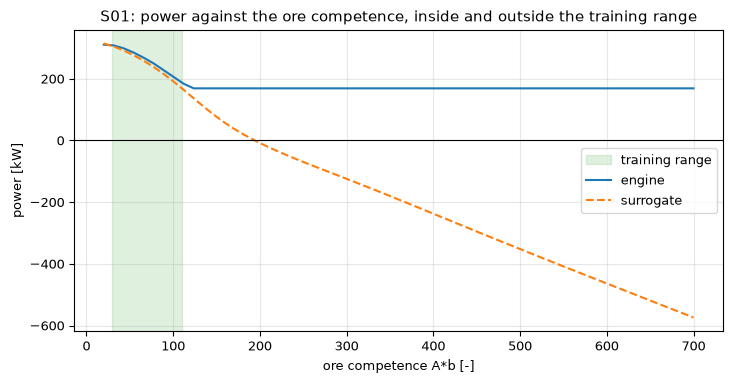

In [8]:
# Plot the power of the network and of the engine against the ore competence, with the training range shaded
grid = np.linspace(20, 700, 60)
points = [replace(base, ore_axb=float(a), ore_wi=sweep.wi_of_axb(a)) for a in grid]
fig, ax = plt.subplots()
ax.axvspan(*domain["ore_axb"], color="tab:green", alpha=0.15, label="training range")
ax.plot(grid, [evaluate(p).power_kw for p in points], label="engine")
ax.plot(grid, [surrogate_graph(p, surrogate_bundle, models_dir)["power_kw"] for p in points], "--", label="surrogate")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("ore competence A*b [-]")
ax.set_ylabel("power [kW]")
ax.set_title("S01: power against the ore competence, inside and outside the training range")
ax.legend()
fig.tight_layout()
plt.show()

The two curves agree in the green band and part company at its right edge: the network's line falls below zero while the engine's flattens. The figure shows the failure mode of a learned surrogate in one picture, an unconstrained extrapolation, and the engine's own envelope gate does not catch it either at A*b, which the gate does not test. What follows for use is simple: the network may answer inside the box of its training ranges and the product must check the box on the input, which a range test does exactly and for free, rather than rely on a detector of the output.

**What the autoencoder does at the surveys.** The survey points are calibrated, and the autoencoder is not blind to them: its alarms are the question of this step. The cell scores the engine's result at the ten surveys in three variants of the same operating points: as the surveys are (calibrated), with the calibration switched off at the calibrated lane's ore competence A*b = 677 (the extrapolation of the sweep above), and with the calibration off and the ore at A*b = 100 inside the range. If the alarms were detecting the extrapolation of the ore, they would follow A*b; if they follow the calibration, they respond to something else. For each variant it prints the number of alarms, the median score against the threshold, and the mean power of the engine's result.

In [9]:
# The autoencoder on the ten surveys: calibrated results, and the same points with the calibration off
variants = {"calibrated": calibrated, "calibration off, A*b = 677": far, "calibration off, A*b = 100": inside}
print("alarm threshold:", anomaly_bundle["threshold_p99"])
for name, points in variants.items():
    results = [evaluate(o) for o in points]
    verdicts = [anomaly_graph(r, anomaly_bundle, models_dir) for r in results]
    scores = np.array([v["score"] for v in verdicts])
    power = np.mean([r.power_kw for r in results])
    alarms = sum(v["is_anomaly"] for v in verdicts)
    print(f"{name:28s} alarms {alarms:2d} of 10 | median score {np.median(scores):.3f} | mean power {power:6.1f} kW")

alarm threshold: 0.24454
calibrated                   alarms  8 of 10 | median score 0.299 | mean power  401.1 kW
calibration off, A*b = 677   alarms  0 of 10 | median score 0.086 | mean power  133.7 kW
calibration off, A*b = 100   alarms  0 of 10 | median score 0.074 | mean power  145.6 kW


The autoencoder alarms on 8 of the 10 calibrated results, and on none of the same ten points once the calibration is off, whether the ore sits at the calibrated A*b = 677 or inside the training range at 100. The alarms therefore do not detect the extrapolation of the ore, which is the same in the first two variants; they respond to the signature of the calibrated lane's result. The mean power column shows one difference of the signature: the calibrated form $1.30\,P_d + 110$ kW puts the power of the result at about three times the level of the uncalibrated engine, a combination that the training sweep may never have produced. This notebook does not isolate power, because the calibrated lane also changes the P80 and the throughput (notebook 02 of topic 05 compares the two lanes), so power is the largest difference in relative terms and not a proven cause: the autoencoder reads the whole signature as off-manifold. The alarm at the surveys is real and right for a wrong reason: it flags that the results are not of the kind the network emulates, and it says nothing about the ore, so it cannot be offered as the extrapolation detector that the sweep above showed it is not.

**The rule that refuses it.** The product does not leave that range test to the reader. Both model contracts record the training range of every continuous input for every machine (`training.input_ranges`, written by the training stage from the sweep's own ranges), and one applicability rule decides, in the pipeline and in the browser alike: a model applies to an operating point only when the point is not calibrated, because the models emulate the uncalibrated engine, and every continuous input lies inside its machine's range. Where it does not apply, the slot's baseline answers, labelled with the reason: the engine for the surrogate, the envelope gate for the autoencoder. The cell asks the slots, through the pipeline's wrappers, the questions the raw network answered above.

In [10]:
# Ask the slot, with the applicability rule, about the ten surveys and about the same points with the calibration off
verdicts = [applicability(o, surrogate_bundle) for o in calibrated]
refused = sum(not ok for ok, _ in verdicts)
print("surveys the rule refuses:", refused, "of 10 | reasons:", dict(Counter(tuple(r) for _, r in verdicts)))
uncalibrated = [replace(o, calibrated=False) for o in calibrated]
reasons = Counter(tuple(applicability(o, surrogate_bundle)[1]) for o in uncalibrated)
print("the same points with the calibration off:", dict(reasons))
slot_answers = [surrogate_predict(o, models_dir) for o in calibrated]
print("provenance of the surrogate slot at the ten surveys:", dict(Counter(p for _, p in slot_answers)))
own = all(a == engine_outputs(evaluate(o)) for (a, _), o in zip(slot_answers, calibrated))
print("the slot's answer is the engine's own at every survey:", own)
raw_power = surrogate_graph(calibrated[0], surrogate_bundle, models_dir)["power_kw"]
slot_power = round(slot_answers[0][0]["power_kw"], 1)
print("power at survey 1 [kW], slot:", slot_power, "| raw network:", round(raw_power, 1))
anomaly_slot = [anomaly_score(evaluate(o), models_dir) for o in calibrated]
print("provenance of the autoencoder slot at the ten surveys:", dict(Counter(p for _, p in anomaly_slot)))
print("keys of the autoencoder slot's answer:", sorted(anomaly_slot[0][0]))

surveys the rule refuses: 10 of 10 | reasons: {('calibrated_case',): 10}
the same points with the calibration off: {('outside_training_range:ore_axb',): 8, ('outside_training_range:feed_x63_mm', 'outside_training_range:ore_axb'): 2}
provenance of the surrogate slot at the ten surveys: {'baseline': 10}
the slot's answer is the engine's own at every survey: True
power at survey 1 [kW], slot: 408.3 | raw network: -572.8
provenance of the autoencoder slot at the ten surveys: {'baseline': 10}
keys of the autoencoder slot's answer: ['is_anomaly']


The rule refuses all ten surveys, each for one reason, `calibrated_case`: they run the calibrated fit and the models emulate the uncalibrated engine. With the calibration off the same points would still be refused, eight for the ore competence alone and two (surveys 3 and 5) also for the feed size, the list the earlier cell printed. The surrogate slot therefore answers every survey with the engine's own values and the provenance `baseline`: at survey 1 it gives 408.3 kW where the raw network gives -572.8 kW. The autoencoder slot does the same: its answer is the envelope gate's verdict alone, with no score. The raw readers stay in this notebook as the evidence of why the rule exists; the product's views and its bake never show their numbers at a point the rule refuses.

## Results

**Answer:** the surrogate approach is accurate against its teacher, and says about the plant what the teacher says: on a small independent draw of 276 points its test-set score is R squared 0.9971 for P80 and 0.9984 for the throughput. At the ten surveys, with the ore at the edge of the training range, the surrogate's mean absolute throughput error against the measurement is 24.78 percent, the synthetic engine's 21.72 and the calibrated backbone's 11.55: the network inherits the teacher's error and adds about 3 points. Fed the calibrated lane's ore, A*b = 677 against a training range of 30 to 110, it returns between 2275.6 and 2528.1 t/h at every survey (118.20 percent mean error) and, at survey 1, a power of -572.8 kW where the engine gives 408.3 kW.

The autoencoder's two behaviours must be kept apart. On the uncalibrated A*b sweep of S01 it gives no alarm at any of the six points, since the engine's result is ordinary there: for an input far outside the training range that the engine saturates, it is blind. On the ten calibrated surveys it alarms on 8 of 10, but it does not alarm on the same ten points with the calibration off, at A*b = 677 (0 of 10) or at 100 (0 of 10), where the mean power of the result is 133.7 and 145.6 kW against 401.1 kW calibrated. Its alarms at the surveys therefore respond to the signature of the calibrated lane, and they are not a detection of the ore extrapolation.

The first figure shows the gap to the plant is the teacher's, the second the failure past the range. A validator would conclude that a test-set R squared validates the emulation and nothing else, that the product's surrogate must be guarded on its input range and not only on an output detector, and that the real lane, calibrated and measured, is the evidence that the engine, not the network, brings to the plant. The product therefore applies the range test to the input: its two contracts record the training ranges, and one rule, the same in the pipeline and in the browser, refuses the surrogate and the autoencoder at all ten surveys, so the engine and the envelope gate answer there, labelled with the reason. These are the conclusions of a measurement on the product's own network; the paper's figures for its own circuit are not tested here.

## Summary

The learned-surrogate approach is validated against the model it emulates, and the product's network meets that bar; what it says about the plant is what its teacher says, less well. The network extrapolates without limit outside its training box, and the autoencoder does not see it when the engine saturates; its alarms at the surveys belong to the calibrated lane's signature and not to the ore. A range test on the input sees the extrapolation, and the product now runs that test, from the ranges its contracts record, and answers with the engine or the envelope gate wherever the models do not apply. For the plant, the engine's calibrated lane and its held-out validation (topic 06) are the evidence, and the surrogate is a fast approximation to use inside its box.

## References

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919